# Notebook 3 — Clusters

# Capstone Project | Liga <a class="anchor" id="Cpstone"></a>

**Authors:**\
Maria Margarida Mouteira Guerreiro Romero Antelo <a20243063@pbs.up.pt>\
Mariana Chaves Santos <a20243060@pbs.up.pt>\
Mónica Isabel da Silva Simões <a20250187@pbs.up.pt>\
Hugo Miguel Carvalho da Silva Glória <a20250093@pbs.up.pt>\
Rui Alexandre Paiva Santos <a20160686@pbs.up.pt>
>
> Publication Date: October 2025

**Table of contents:**
1. [Install required packages](#required_packages)
2. [Define program variables and setup db connection](#operators)
3. [Declare database manager helping functions](#db_manager)
4. [Declare technician assignment function](#logical_operators)
5. [Declare random intervencion close](#comparison_operators)
6. [Main program](#main)


## Setup working directories <a class="anchor" id="folder_structure"></a>
---

In [403]:
import sys 
import os 
from dotenv import load_dotenv

# Determinar o diretório raiz do projeto
current_dir = os.getcwd()  
project_root = os.path.dirname(current_dir)
    
# Define paths baseados na estrutura do container
PythonScriptsPath = os.path.join(project_root, 'Python')
DataFilesPath = os.path.join(project_root, 'Base de Dados')
NotebooksPath = os.path.join(project_root, 'Notebooks')
log_path = os.path.join(project_root, 'logs')

# Criar diretório de logs se não existir
os.makedirs(log_path, exist_ok=True)

# Carregar .env se existir
dotenv_path = os.path.join(project_root, '.env')
if os.path.exists(dotenv_path):
    load_dotenv(dotenv_path)
    print("✓ Loaded environment variables from .env file.")

# Adicionar paths ao sys.path
paths_to_add = [
    ('PythonScriptsPath', PythonScriptsPath),
    ('project_root', project_root),
    ('NotebooksPath', NotebooksPath)
]

# DataFilesPath normalmente não precisa estar no sys.path (é só para dados)
# Mas se tiver scripts Python lá, pode adicionar

for name, path in paths_to_add:
    if os.path.exists(path):
        if path not in sys.path:
            sys.path.insert(0, path)
            print(f"✓ Added '{name}' to path: {path}")
    else:
        print(f"⚠ '{name}' não existe: {path}")


# Crie o ficheiro __init__.py no seu notebook
init_file_path = os.path.join(PythonScriptsPath, '__init__.py')

if not os.path.exists(init_file_path):
    with open(init_file_path, 'w') as f:
        pass  # Cria um ficheiro vazio
    print(f"✓ Ficheiro __init__.py criado em: {init_file_path}")


# Verificação de configuração
print(f"\n{'='*60}")
print("CONFIGURAÇÃO DE PATHS")
print(f"{'='*60}")
print(f"Working directory:   {os.getcwd()}")
print(f"Project root:        {project_root}")
print(f"Notebooks:           {NotebooksPath}")
print(f"Python scripts:      {PythonScriptsPath}")
print(f"Data files:          {DataFilesPath}")
print(f"Logs:                {log_path}")
print(f"{'='*60}\n")



CONFIGURAÇÃO DE PATHS
Working directory:   /home/jovyan/Notebooks
Project root:        /home/jovyan
Notebooks:           /home/jovyan/Notebooks
Python scripts:      /home/jovyan/Python
Data files:          /home/jovyan/Base de Dados
Logs:                /home/jovyan/logs




## Import required modules <a class="anchor" id="required_modules"></a>
---

In [404]:
# Personalized imports
from HelperFunctions import ( # type: ignore
    Logger as log,
    DataCleaning as dc,
    FileOperations as fo,
    DataValidation as dv,
    DataAnalysis as da,
    Distance as dist,
    DatabaseManager as dbm,
    LigaSchedule as ls
)


# Standard library imports
import getpass
import importlib.util
import re
from collections import defaultdict, Counter
from datetime import timedelta, datetime, time
from itertools import combinations

# Third-party imports
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from geopy.distance import geodesic
from IPython.display import display
from joblib import dump, load
import json
from lightgbm import LGBMRegressor
from scipy import stats
from statsmodels.stats.multitest import multipletests
from typing import Optional, List, Dict, Any
from xgboost import XGBRegressor



# Scikit-learn imports
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor



## Main program <a class="anchor" id="main"></a>
---

In [405]:
# Cria o log do programa principal
logger_main = log.setup_logger('main')

# Carregamento da tabela via csv, com todos os valores iniciais da liga

# Define the path to the stadia file
base_data_file_path = DataFilesPath + '/liga_base_data.csv'


logger_main.info("Carregar os dados da liga...")

# Bloco de tratamento de erros para carregamento do ficheiro
try:
    logger_main.info(f"Tentando carregar ficheiro de dados da liga: {base_data_file_path}")

    # Tentar carregar o ficheiro CSV
    logger_main.info("Carregando dados da liga com separador ';' e decimal '.'...")
    df_processed = fo.safe_read_csv(base_data_file_path, logger_main, sep=';', decimal='.', low_memory=False)

    if df_processed.empty:
        logger_main.warning("O ficheiro de dados da liga foi carregado mas está vazio.")
        raise ValueError("O ficheiro de dados da liga está vazio.")

    # Verificar se as colunas necessárias existem
    required_columns = ['Competicao', 'Lotacao_Casa', 'Latitude_Casa', 'Longitude_Casa']
    missing_columns = [col for col in required_columns if col not in df_processed.columns]

    if missing_columns:
        logger_main.error(f"Colunas obrigatórias em falta: {missing_columns}")
        raise ValueError(f"O ficheiro de dados da liga não contém as colunas necessárias: {missing_columns}")

    logger_main.info("Todas as colunas necessárias estão presentes no ficheiro.")

    print("\nDataFrame with location information:")
    print(df_processed)
    print(f"\nNúmero de linhas no df_processed: {len(df_processed)}")

except pd.errors.ParserError as e:
    logger_main.error(f"Erro ao analisar o ficheiro CSV: {e}")
    raise
except Exception as e:
    logger_main.error(f"Erro desconhecido ao carregar o ficheiro: {e}")
    raise

INFO - O log 'logs/main.log' é recente. O novo conteúdo será anexado.

DataFrame with location information:
       Epoca               Competicao                  Data_Hora  \
0     200708              Allianz Cup  2007-08-04 17:00:00+00:00   
1     200708              Allianz Cup  2007-08-04 17:00:00+00:00   
2     200708              Allianz Cup  2007-08-05 16:00:00+00:00   
3     200708              Allianz Cup  2007-08-05 16:00:00+00:00   
4     200708              Allianz Cup  2007-08-05 16:00:00+00:00   
...      ...                      ...                        ...   
9609  202425  Liga Portugal Meu Super  2025-05-16 20:30:00+00:00   
9610  202425  Liga Portugal Meu Super  2025-05-16 20:30:00+00:00   
9611  202425  Liga Portugal Meu Super  2025-05-17 11:00:00+00:00   
9612  202425  Liga Portugal Meu Super  2025-05-17 14:00:00+00:00   
9613  202425  Liga Portugal Meu Super  2025-05-17 14:00:00+00:00   

         EquipaCasa      EquipaFora  Jornada  Espetadores  \
0       CD Tro

In [406]:
# Count total rows before filtering
total_rows = len(df_processed)
zero_spectators = df_processed[df_processed['Espetadores'] == 0]
zero_count = len(zero_spectators)

zero_percentage = (zero_count / total_rows) * 100

print(f"Total rows: {total_rows}")
print(f"Rows with zero spectators: {zero_count}")
print(f"Percentage of zero spectators: {zero_percentage:.2f}%")

print("\nBreakdown by competition:")
print(zero_spectators['Competicao'].value_counts())

# Filter out rows with zero spectators
df_processed_filtered = df_processed[df_processed['Espetadores'] != 0]

print(f"\nAfter filtering:")
print(f"Rows removed: {total_rows - len(df_processed_filtered)}")
print(f"Rows remaining: {len(df_processed_filtered)}")
print(f"Percentage remaining: {(len(df_processed_filtered)/total_rows)*100:.2f}%")

Total rows: 9614
Rows with zero spectators: 55
Percentage of zero spectators: 0.57%

Breakdown by competition:
Competicao
Liga Portugal Betclic      24
Liga Portugal Meu Super    19
Allianz Cup                12
Name: count, dtype: int64

After filtering:
Rows removed: 55
Rows remaining: 9559
Percentage remaining: 99.43%



Primeiras linhas do DataFrame com a coluna 'Espetadores_log':
   Espetadores  Espetadores_log
0        622.0         6.434547
1        622.0         6.434547
2       1035.0         6.943122
3       1035.0         6.943122
4       1231.0         7.116394


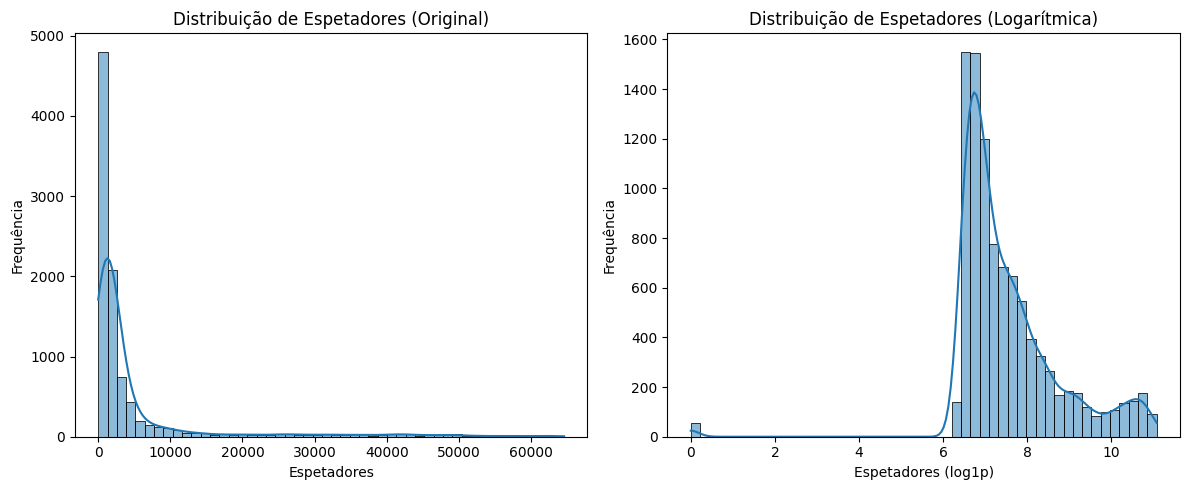


Estatísticas Descritivas para Espetadores (logarítmica):
        Espetadores  Espetadores_log
count   9614.000000      9614.000000
mean    4892.804464         7.533765
std    10123.375959         1.260569
min        0.000000         0.000000
25%      846.000000         6.741701
50%     1292.654400         7.165226
75%     3015.000000         8.011687
max    64591.000000        11.075846


In [407]:
#NORMALIZAÇÃO DA VARIÁVEL ESPETADORES

df_processed_filtered = df_processed.query('Espetadores != 0')

print("\nPrimeiras linhas do DataFrame com a coluna 'Espetadores_log':")
print(df_processed[['Espetadores', 'Espetadores_log']].head())

# Opcional: Visualizar a distribuição antes e depois da transformação logarítmica
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed['Espetadores'], kde=True, bins=50)
plt.title('Distribuição de Espetadores (Original)')
plt.xlabel('Espetadores')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed['Espetadores_log'], kde=True, bins=50)
plt.title('Distribuição de Espetadores (Logarítmica)')
plt.xlabel('Espetadores (log1p)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

# Opcional: Verificar estatísticas descritivas após a transformação
print("\nEstatísticas Descritivas para Espetadores (logarítmica):")
print(df_processed[['Espetadores', 'Espetadores_log']].describe())


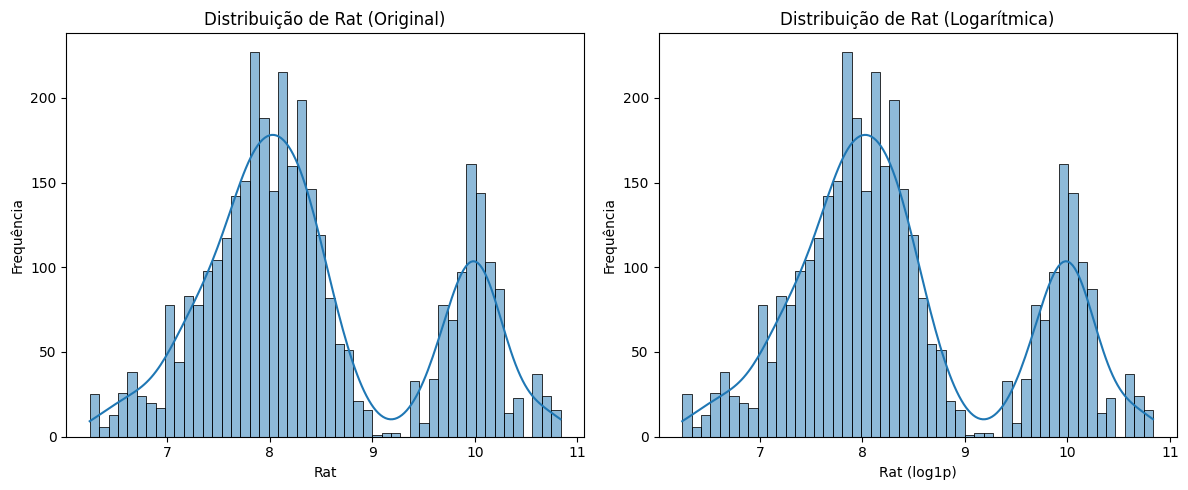

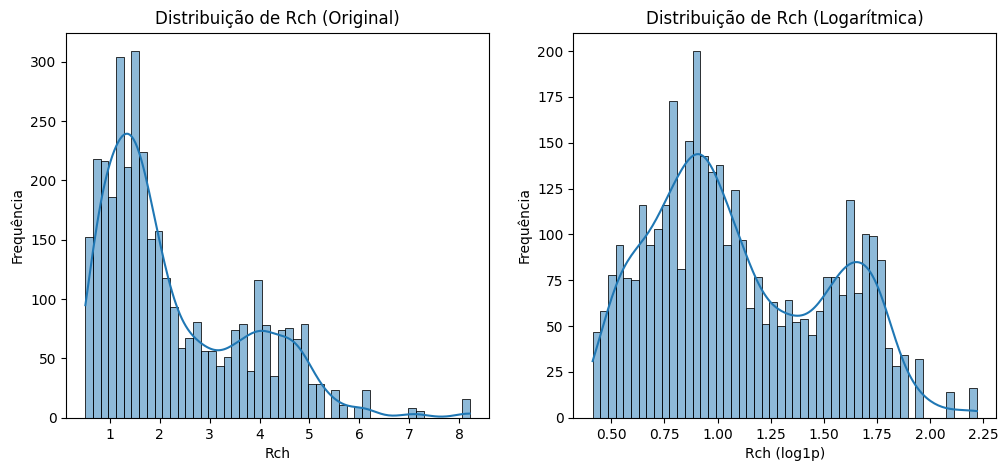

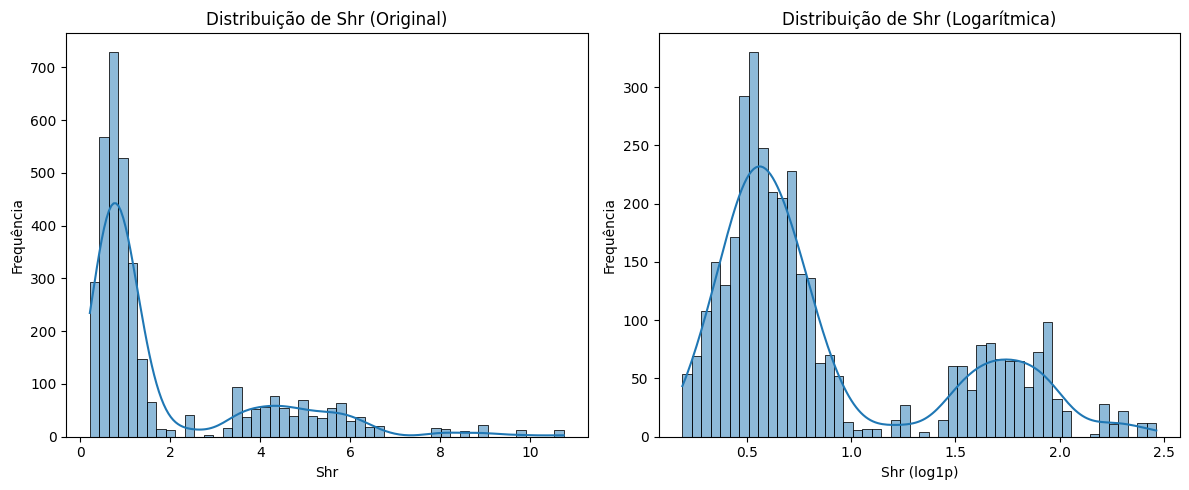

In [408]:
#NORMALIZAÇÃO DAS VARIÁVEIS RAT, RCH E SHR

df_processed_filtered = df_processed.query('Rat != 0 & Rch != 0 & Shr != 0')

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed_filtered['Rat_log'], kde=True, bins=50)
plt.title('Distribuição de Rat (Original)')
plt.xlabel('Rat')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed_filtered['Rat_log'], kde=True, bins=50)
plt.title('Distribuição de Rat (Logarítmica)')
plt.xlabel('Rat (log1p)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed_filtered['Rch'], kde=True, bins=50)
plt.title('Distribuição de Rch (Original)')
plt.xlabel('Rch')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed_filtered['Rch_log'], kde=True, bins=50)
plt.title('Distribuição de Rch (Logarítmica)')
plt.xlabel('Rch (log1p)')
plt.ylabel('Frequência')
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed_filtered['Shr'], kde=True, bins=50)
plt.title('Distribuição de Shr (Original)')
plt.xlabel('Shr')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed_filtered['Shr_log'], kde=True, bins=50)
plt.title('Distribuição de Shr (Logarítmica)')
plt.xlabel('Shr (log1p)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

Task
Create a new column new_schedule in the df_processed DataFrame that maps the existing Weekday_name and Hour to the closest available time slot for each competition, based on the provided schedules for "Liga Portugal Betclic" and "Liga Portugal Meu Super".

Define schedules
Subtask:
Define the available time slots for each competition (Liga Portugal Betclic and Liga Portugal Meu Super) as dictionaries or similar data structures.

Reasoning: Defining the schedules for each competition as dictionaries is the first step towards mapping the existing game times to these schedules.

Separate into two different datasets

In [409]:
df_betclic = df_processed[df_processed['Competicao'] == 'Liga Portugal Betclic'].copy()
df_meu_super = df_processed[df_processed['Competicao'] == 'Liga Portugal Meu Super'].copy()

print("DataFrame for Liga Portugal Betclic:")
print(df_betclic.head())

print("\nDataFrame for Liga Portugal Meu Super:")
print(df_meu_super.head())

DataFrame for Liga Portugal Betclic:
      Epoca             Competicao                  Data_Hora    EquipaCasa  \
327  201213  Liga Portugal Betclic  2012-08-17 20:15:00+00:00  SC Olhanense   
328  201213  Liga Portugal Betclic  2012-08-18 18:14:00+00:00    Rio Ave FC   
329  201213  Liga Portugal Betclic  2012-08-18 20:15:00+00:00    SL Benfica   
330  201213  Liga Portugal Betclic  2012-08-19 16:00:00+00:00   CD Nacional   
331  201213  Liga Portugal Betclic  2012-08-19 18:00:00+00:00  FC PFerreira   

        EquipaFora  Jornada  Espetadores  TaxaOcupacao_decimal     Rat    Shr  \
327  Estoril Praia      1.0       2108.5                0.1566  2852.0  4.115   
328     Marítimo M      1.0        812.0                0.1152  1953.5  1.080   
329       SC Braga      1.0        812.0                0.8209  1471.5  1.235   
330     Vitória FC      1.0          0.0                0.2708  1875.5  0.585   
331  Moreirense FC      1.0      14897.0                0.2361     0.0  6.200   

 

**HEATMAPS**

Heatmaps divididos inicialmente por campeonatos. A variável CampeaoAnterior aparece a vazio porque o campeão sobe para a liga Betclic

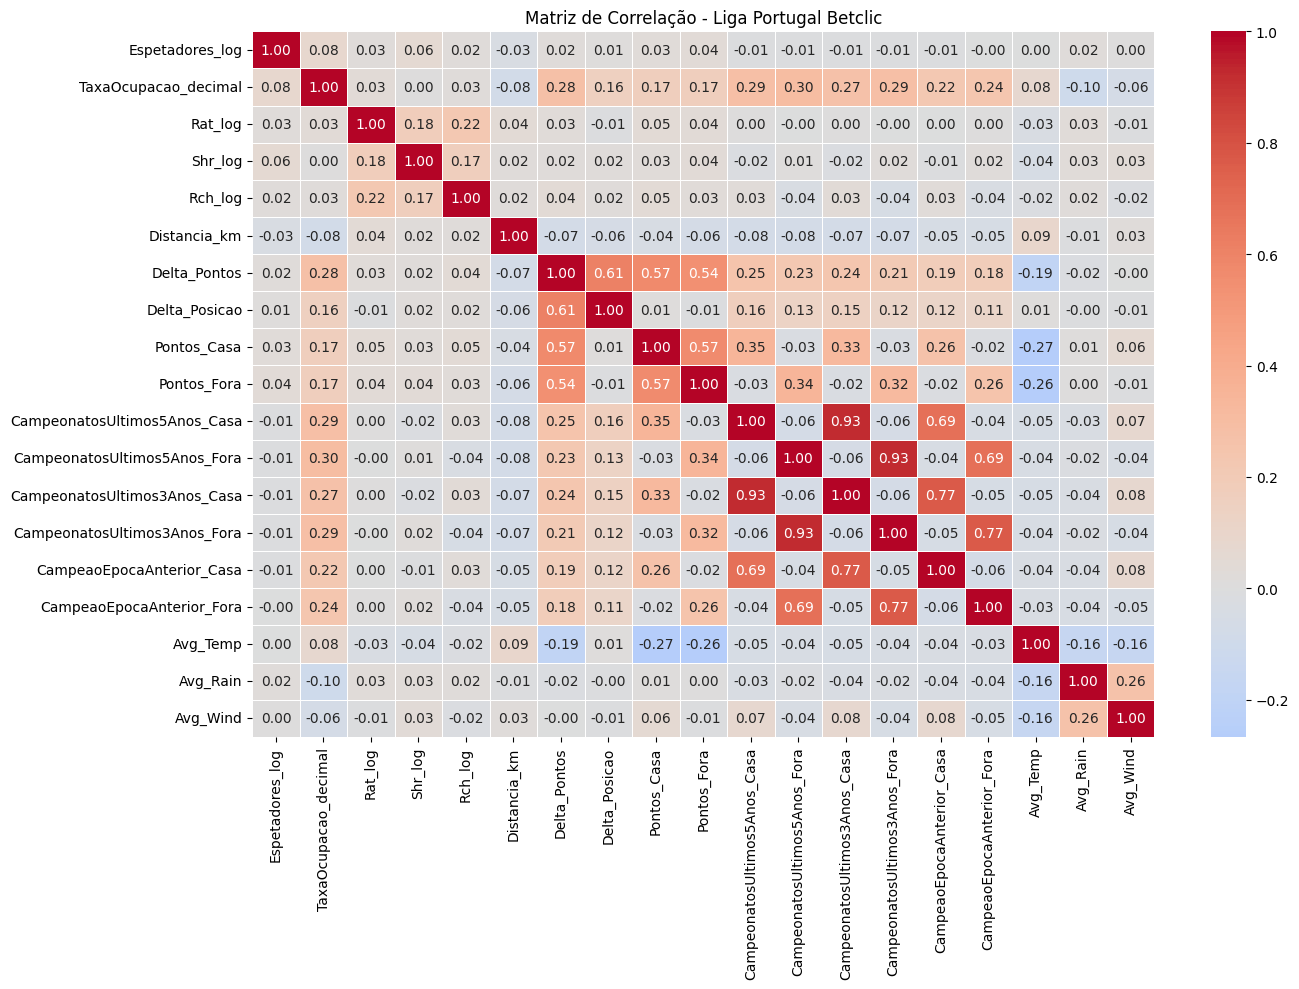

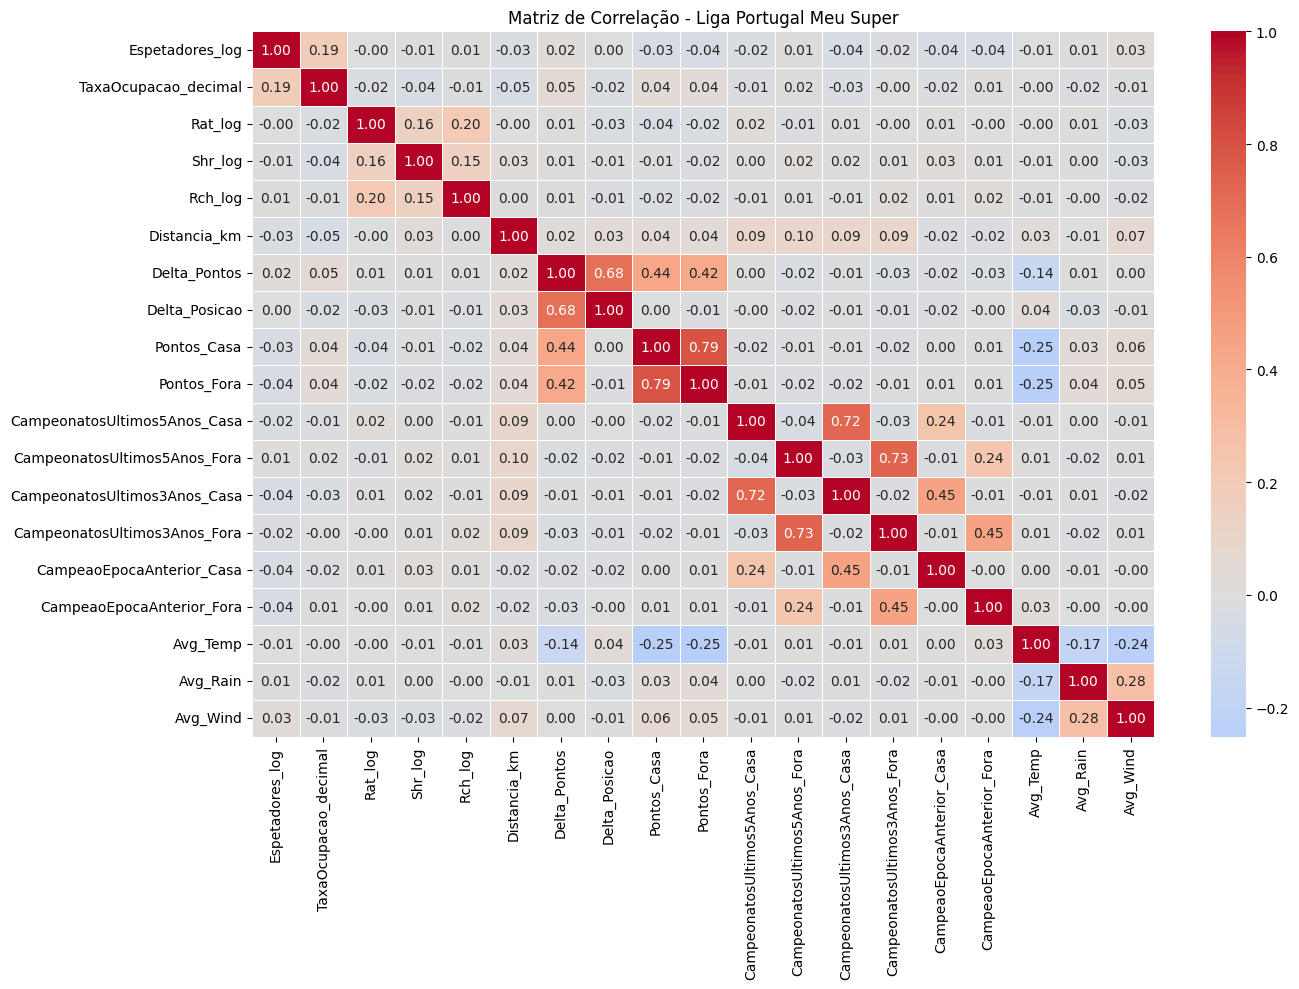

In [433]:

# Variáveis que vamos analisar
features_corr = [
    'Espetadores_log',
    'TaxaOcupacao_decimal',
    'Rat_log',
    'Shr_log',
    'Rch_log',
    'Distancia_km',
    'Delta_Pontos',
    'Delta_Posicao',
    'Pontos_Casa',
    'Pontos_Fora',
    'CampeonatosUltimos5Anos_Casa',
    'CampeonatosUltimos5Anos_Fora',
    'CampeonatosUltimos3Anos_Casa',
    'CampeonatosUltimos3Anos_Fora',
    'CampeaoEpocaAnterior_Casa',
    'CampeaoEpocaAnterior_Fora',
    'Avg_Temp',
    'Avg_Rain',
    'Avg_Wind'
]

# Garantir que só usamos colunas que existem
features_corr = [col for col in features_corr if col in df_processed.columns]

# Função para desenhar heatmap para uma liga específica
def plot_corr_heatmap(df, liga, features):
    subset = df[df['Competicao'] == liga][features].dropna()
    corr = subset.corr()
    
    plt.figure(figsize=(14, 10))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True, linewidths=0.5)
    plt.title(f"Matriz de Correlação - {liga}")
    plt.tight_layout()
    plt.show()

# Heatmap para cada liga
plot_corr_heatmap(df_processed, "Liga Portugal Betclic", features_corr)
plot_corr_heatmap(df_processed, "Liga Portugal Meu Super", features_corr)

**HEATMAP - Sem o impacto dos 3 grandes (retirada de variáveis CampeonatosUltimos3Anos e CampeonatosUltimos5Anos)** - Mariana

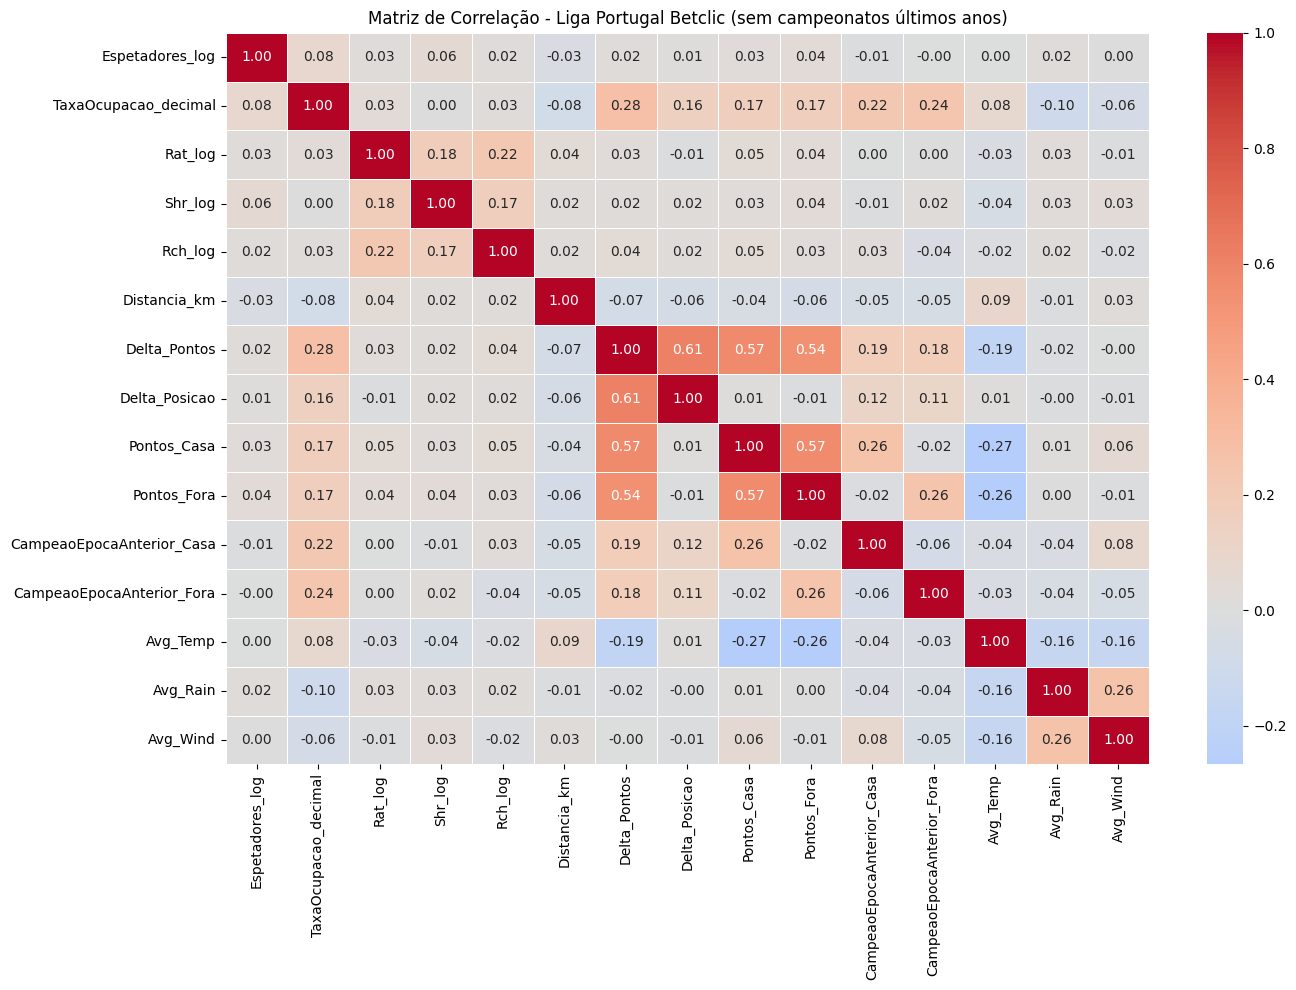

In [434]:
# Variáveis selecionadas para Betclic (sem campeonatos últimos anos)
features_corr_betclic_reduced = [
    # Audiência e estádio
    'Espetadores_log',
    'TaxaOcupacao_decimal',
    'Rat_log',
    'Shr_log',
    'Rch_log',
    'Distancia_km',
    
    # Competitividade (classificação/jogo)
    'Delta_Pontos',
    'Delta_Posicao',
    'Pontos_Casa',
    'Pontos_Fora',
    
    # Campeão da época anterior
    'CampeaoEpocaAnterior_Casa',
    'CampeaoEpocaAnterior_Fora',
    
    # Condições externas (clima)
    'Avg_Temp',
    'Avg_Rain',
    'Avg_Wind'
]

# Garantir que só usamos colunas que existem no df
features_corr_betclic_reduced = [
    col for col in features_corr_betclic_reduced if col in df_processed.columns
]

# Filtrar só jogos da Liga Portugal Betclic
subset = df_processed[df_processed['Competicao'] == "Liga Portugal Betclic"][features_corr_betclic_reduced].dropna()

# Calcular correlação
corr = subset.corr()

# Plotar heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            cbar=True, linewidths=0.5)
plt.title("Matriz de Correlação - Liga Portugal Betclic (sem campeonatos últimos anos)")
plt.tight_layout()
plt.show()

**CLUSTERS** - MARIANA

Liga Portugal Betclic

Número de registros para clustering: 3846
Features utilizadas: ['Espetadores_log', 'Rch_log', 'Distancia_km', 'Delta_Pontos']


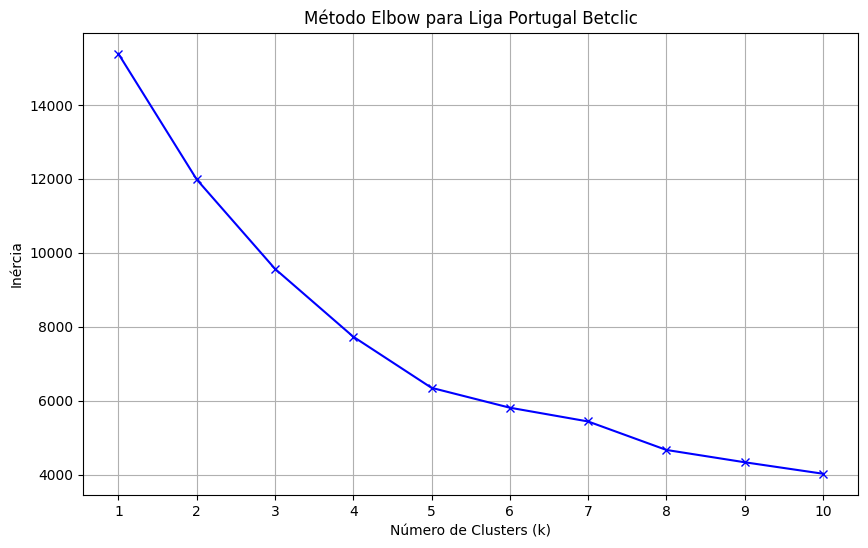


Análise para n_clusters = 4

Tamanho de cada cluster:
cluster_k4
0     765
1    1312
2    1192
3     577
Name: count, dtype: int64

Média das variáveis originais por cluster:
            Espetadores_log   Rch_log  Distancia_km  Delta_Pontos
cluster_k4                                                       
0                  7.408352  0.731991   1217.465624      7.942484
1                  7.788963  1.204731    190.178733      7.298780
2                  7.313100  0.171544    170.055175      7.551174
3                  7.556564  0.829406    266.097792     33.227036


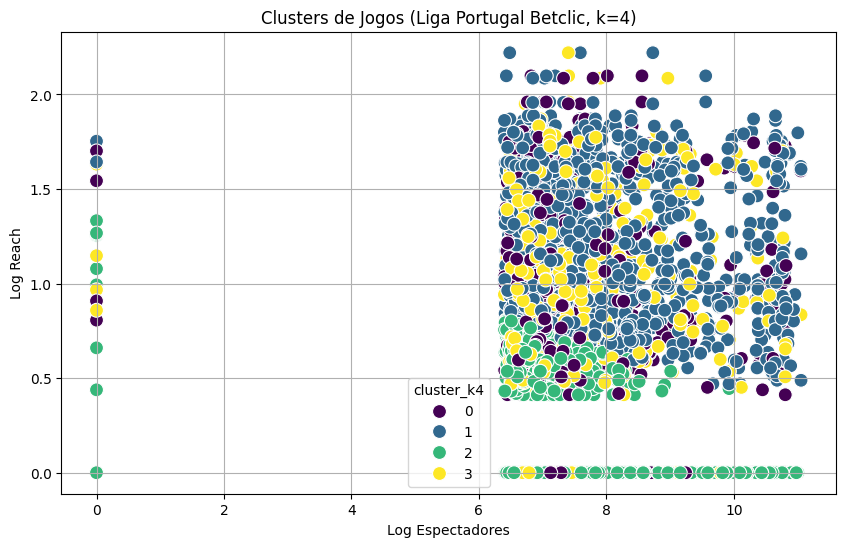


Análise para n_clusters = 5

Tamanho de cada cluster:
cluster_k5
0     495
1    1013
2    1100
3     721
4     517
Name: count, dtype: int64

Média das variáveis originais por cluster:
            Espetadores_log   Rch_log  Distancia_km  Delta_Pontos
cluster_k5                                                       
0                  9.849427  0.725908    272.142632      9.012121
1                  7.078474  0.147418    170.459668      7.873643
2                  7.119967  1.225720    187.671523      7.312727
3                  7.240941  0.731066   1222.810724      7.925104
4                  7.476246  0.850250    273.981510     34.100580


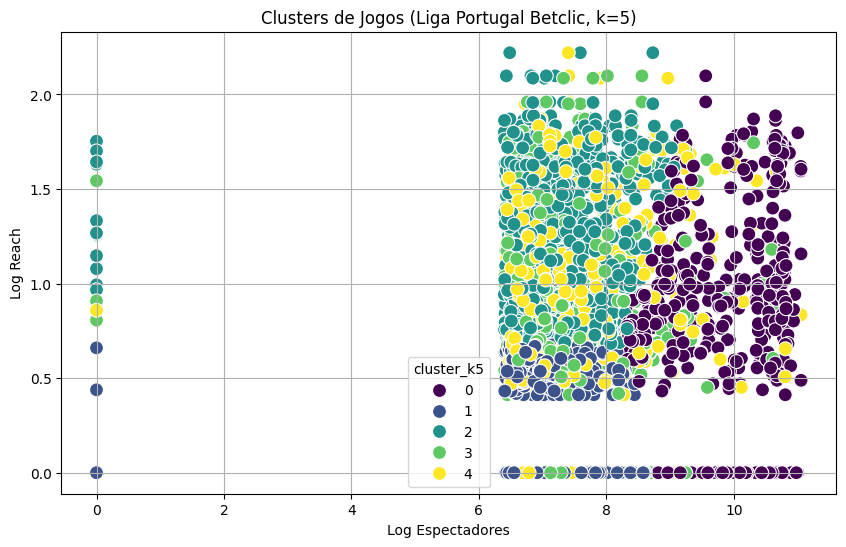

In [435]:
# features = ['Espetadores_log', 'Rch_log', 'Distancia_km', 'Delta_Pontos']

# --- 1. Filtrar o DataFrame para a competição desejada ---
competition_to_analyze = 'Liga Portugal Betclic'
df_filtered = df_processed[df_processed['Competicao'] == competition_to_analyze].copy()

# Definir as variáveis de análise
features = ['Espetadores_log', 'Rch_log', 'Distancia_km', 'Delta_Pontos']

# --- 2. Preparar os dados para clustering (sem PCA) ---
# Filtrar apenas os registros sem valores nulos nas features
df_clustering = df_filtered[features].dropna()

# Normalizar as variáveis
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clustering)

print(f"Número de registros para clustering: {len(df_clustering)}")
print(f"Features utilizadas: {features}")

# --- 3. Determinar o número de clusters com o Método Elbow ---
inertia = []
k_range = range(1, min(11, len(df_clustering)))

for k in k_range:
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(df_scaled)  # Usar as features escaladas diretamente
    inertia.append(kmeans_model.inertia_)

# Plotar o gráfico Elbow para ajudar a decidir
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, 'bx-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.title(f'Método Elbow para {competition_to_analyze}')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Análise para n_clusters = 4
n_clusters_4 = 4
print(f"\n{'='*50}")
print(f"Análise para n_clusters = {n_clusters_4}")
print(f"{'='*50}")

kmeans_4 = KMeans(n_clusters=n_clusters_4, random_state=42, n_init=10)
cluster_labels_4 = kmeans_4.fit_predict(df_scaled)

# Adicionar os labels de cluster ao dataframe filtrado (apenas para registros válidos)
df_clustering_copy = df_clustering.copy()
df_clustering_copy['cluster_k4'] = cluster_labels_4

print("\nTamanho de cada cluster:")
print(df_clustering_copy['cluster_k4'].value_counts().sort_index())

print("\nMédia das variáveis originais por cluster:")
print(df_clustering_copy.groupby('cluster_k4')[features].mean())

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Espetadores_log',
    y='Rch_log',
    hue='cluster_k4',
    data=df_clustering_copy,
    palette='viridis',
    s=100
)
plt.xlabel('Log Espectadores')
plt.ylabel('Log Reach')
plt.title(f'Clusters de Jogos ({competition_to_analyze}, k={n_clusters_4})')
plt.grid(True)
plt.show()

# Análise para n_clusters = 5
n_clusters_5 = 5
print(f"\n{'='*50}")
print(f"Análise para n_clusters = {n_clusters_5}")
print(f"{'='*50}")

kmeans_5 = KMeans(n_clusters=n_clusters_5, random_state=42, n_init=10)
cluster_labels_5 = kmeans_5.fit_predict(df_scaled)

# Adicionar os labels de cluster ao dataframe
df_clustering_copy['cluster_k5'] = cluster_labels_5

print("\nTamanho de cada cluster:")
print(df_clustering_copy['cluster_k5'].value_counts().sort_index())

print("\nMédia das variáveis originais por cluster:")
print(df_clustering_copy.groupby('cluster_k5')[features].mean())

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Espetadores_log',
    y='Rch_log',
    hue='cluster_k5',
    data=df_clustering_copy,
    palette='viridis',
    s=100
)
plt.xlabel('Log Espectadores')
plt.ylabel('Log Reach')
plt.title(f'Clusters de Jogos ({competition_to_analyze}, k={n_clusters_5})')
plt.grid(True)
plt.show()

Liga Portugal Meu Super

Número de registros para clustering: 4920
Features utilizadas: ['Espetadores_log', 'Rch_log', 'Distancia_km', 'Delta_Pontos']


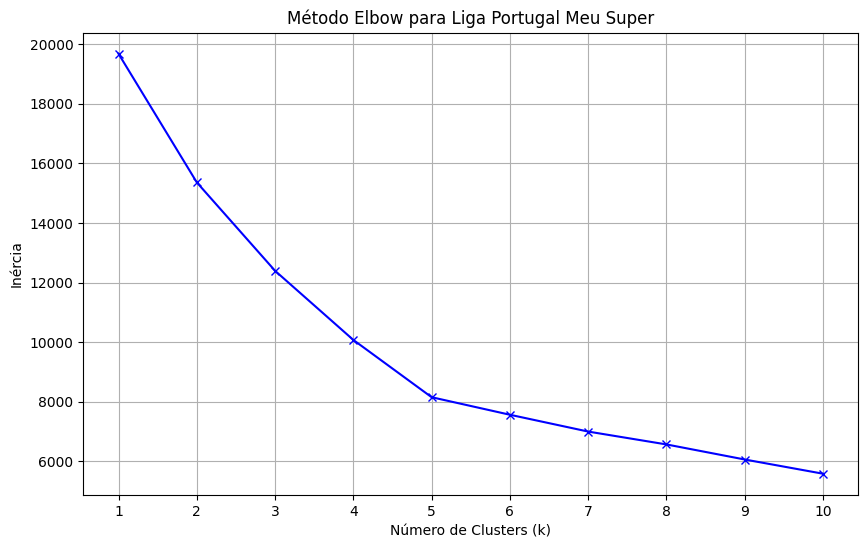


Análise para n_clusters = 4

Tamanho de cada cluster:
cluster_k4
0    1877
1    1508
2     781
3     754
Name: count, dtype: int64

Média das variáveis originais por cluster:
            Espetadores_log   Rch_log  Distancia_km  Delta_Pontos
cluster_k4                                                       
0                  7.692286  1.194942    170.776666      5.322856
1                  7.408884  0.128627    180.103091      5.842175
2                  7.495453  0.735867   1258.162071      7.731114
3                  7.644959  0.780350    231.584975     21.827586


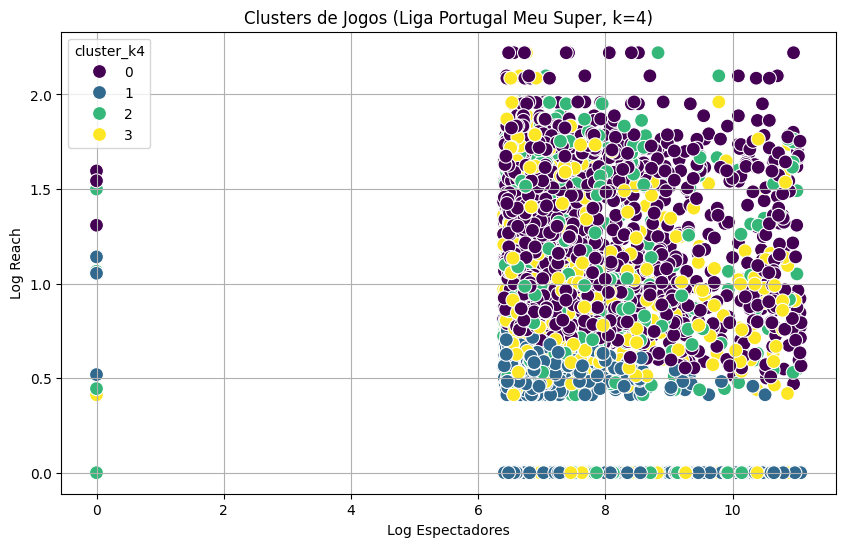


Análise para n_clusters = 5

Tamanho de cada cluster:
cluster_k5
0    1319
1     747
2    1578
3     632
4     644
Name: count, dtype: int64

Média das variáveis originais por cluster:
            Espetadores_log   Rch_log  Distancia_km  Delta_Pontos
cluster_k5                                                       
0                  7.127581  0.121868    181.645829      5.909022
1                  7.394075  0.738455   1265.166401      7.713521
2                  7.160170  1.205317    171.991106      5.513942
3                  9.857874  0.756805    216.709493      7.006329
4                  7.415667  0.787746    242.780121     22.689441


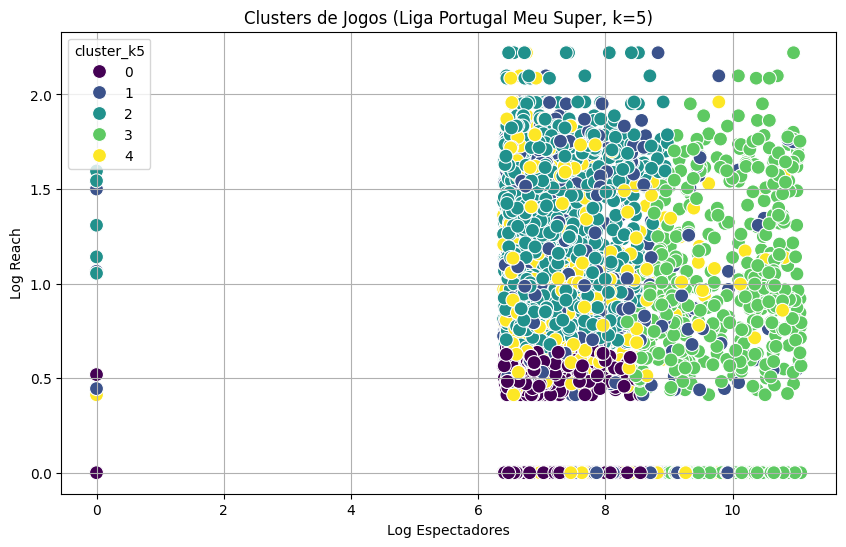

In [436]:
# features = ['Espetadores_log', 'Rch_log', 'Distancia_km', 'Delta_Pontos']

# --- 1. Filtrar o DataFrame para a competição desejada ---
competition_to_analyze = 'Liga Portugal Meu Super'
df_filtered = df_processed[df_processed['Competicao'] == competition_to_analyze].copy()

# Definir as variáveis de análise
features = ['Espetadores_log', 'Rch_log', 'Distancia_km', 'Delta_Pontos']

# --- 2. Preparar os dados para clustering (sem PCA) ---
# Filtrar apenas os registros sem valores nulos nas features
df_clustering = df_filtered[features].dropna()

# Normalizar as variáveis
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clustering)

print(f"Número de registros para clustering: {len(df_clustering)}")
print(f"Features utilizadas: {features}")

# --- 3. Determinar o número de clusters com o Método Elbow ---
inertia = []
k_range = range(1, min(11, len(df_clustering)))

for k in k_range:
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(df_scaled)  # Usar as features escaladas diretamente
    inertia.append(kmeans_model.inertia_)

# Plotar o gráfico Elbow para ajudar a decidir
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, 'bx-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.title(f'Método Elbow para {competition_to_analyze}')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Análise para n_clusters = 4
n_clusters_4 = 4
print(f"\n{'='*50}")
print(f"Análise para n_clusters = {n_clusters_4}")
print(f"{'='*50}")

kmeans_4 = KMeans(n_clusters=n_clusters_4, random_state=42, n_init=10)
cluster_labels_4 = kmeans_4.fit_predict(df_scaled)

# Adicionar os labels de cluster ao dataframe filtrado (apenas para registros válidos)
df_clustering_copy = df_clustering.copy()
df_clustering_copy['cluster_k4'] = cluster_labels_4

print("\nTamanho de cada cluster:")
print(df_clustering_copy['cluster_k4'].value_counts().sort_index())

print("\nMédia das variáveis originais por cluster:")
print(df_clustering_copy.groupby('cluster_k4')[features].mean())

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Espetadores_log',
    y='Rch_log',
    hue='cluster_k4',
    data=df_clustering_copy,
    palette='viridis',
    s=100
)
plt.xlabel('Log Espectadores')
plt.ylabel('Log Reach')
plt.title(f'Clusters de Jogos ({competition_to_analyze}, k={n_clusters_4})')
plt.grid(True)
plt.show()

# Análise para n_clusters = 5
n_clusters_5 = 5
print(f"\n{'='*50}")
print(f"Análise para n_clusters = {n_clusters_5}")
print(f"{'='*50}")

kmeans_5 = KMeans(n_clusters=n_clusters_5, random_state=42, n_init=10)
cluster_labels_5 = kmeans_5.fit_predict(df_scaled)

# Adicionar os labels de cluster ao dataframe
df_clustering_copy['cluster_k5'] = cluster_labels_5

print("\nTamanho de cada cluster:")
print(df_clustering_copy['cluster_k5'].value_counts().sort_index())

print("\nMédia das variáveis originais por cluster:")
print(df_clustering_copy.groupby('cluster_k5')[features].mean())

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Espetadores_log',
    y='Rch_log',
    hue='cluster_k5',
    data=df_clustering_copy,
    palette='viridis',
    s=100
)
plt.xlabel('Log Espectadores')
plt.ylabel('Log Reach')
plt.title(f'Clusters de Jogos ({competition_to_analyze}, k={n_clusters_5})')
plt.grid(True)
plt.show()